# Tier 2: Fusion Agent
This notebook implements the **weighted-score fusion** baseline for the hierarchical insider threat detection system. It combines the four Tier-1 modality scores into a single risk score per user/day.

**Approach:**
1. Apply domain-informed weights reflecting the primary exfiltration channels (File/Device + HTTP)
2. Threshold the fused score for escalation decisions
3. Perform threshold sweep analysis to find optimal operating point
4. Compare against the Week-1 flat Random Forest baseline

**Inputs — finalized, reproducible Tier-1 scores** (`tier1/scores/`, generated by `week3/generate_scores.py` from the finalized MLPs):

| Modality | Model | Ratio |
|:---|:---|:---|
| HTTP | MLP | 6:1 |
| File/Device | MLP | 4:1 |
| Email | MLP | 4:1 |
| Logon | MLP | 4:1 |

The Fusion methodology (weights, threshold procedure, validation/test protocol) is **unchanged**; only the input Tier-1 scores have been corrected, so fresh numerical results are expected.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import recall_score, confusion_matrix, roc_auc_score, roc_curve
from pathlib import Path
from IPython.display import display, Markdown

# Resolve paths
_curr = Path.cwd()
while not (_curr / 'pyproject.toml').exists() and _curr != _curr.parent:
    _curr = _curr.parent
PROJECT_ROOT = _curr
WEEK3_DIR = PROJECT_ROOT / "week3"

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Load Tier 1 Scores (Validation + Test)

In [2]:
# --- Canonical Tier-1 scores (finalized, reproducible) ---
TIER1_SCORES_DIR = PROJECT_ROOT / "tier1" / "scores"

# Validation set -> used ONLY for tuning the escalation threshold
df_val = pd.read_csv(TIER1_SCORES_DIR / "tier1_validation_scores.csv")
# Held-out Test set -> untouched until the final evaluation (Section 5)
df_test = pd.read_csv(TIER1_SCORES_DIR / "tier1_test_scores.csv")

# --- Input provenance checks (fail loudly, no silent renames/drops) ---
required_columns = {"user", "week", "day", "label"}
score_columns = ["logon_score", "email_score", "file_device_score", "http_score"]
for name, d in [("Validation", df_val), ("Test", df_test)]:
    missing = required_columns - set(d.columns)
    assert not missing, f"{name}: missing required columns {missing}"
    for sc in score_columns:
        assert sc in d.columns, f"{name}: missing score column {sc}"
    dup = int(d.duplicated(subset=["user", "week", "day"]).sum())
    assert dup == 0, f"{name}: {dup} duplicate (user, week, day) records"

print("Tier-1 validation score file:", TIER1_SCORES_DIR / "tier1_validation_scores.csv")
print("Tier-1 test score file:      ", TIER1_SCORES_DIR / "tier1_test_scores.csv")
print(f"Validation rows: {len(df_val)} | users: {df_val['user'].nunique()}")
print(f"Test rows:       {len(df_test)} | users: {df_test['user'].nunique()}")
print("Provenance: finalized Tier-1 MLPs -> HTTP 6:1, File/Device 4:1, Email 4:1, Logon 4:1 "
      "(deterministic features, persisted scalers, reproducible inference).")

for name, d in [("Validation", df_val), ("Test", df_test)]:
    print(f"{name}: {len(d)} user/day sequences | positives: {d['label'].sum()} "
          f"({100*d['label'].mean():.2f}%) | users: {d['user'].nunique()}")
df_test.head()


Tier-1 validation score file: C:\insider_threat_detection_project2\tier1\scores\tier1_validation_scores.csv
Tier-1 test score file:       C:\insider_threat_detection_project2\tier1\scores\tier1_test_scores.csv
Validation rows: 61076 | users: 200
Test rows:       61203 | users: 200
Provenance: finalized Tier-1 MLPs -> HTTP 6:1, File/Device 4:1, Email 4:1, Logon 4:1 (deterministic features, persisted scalers, reproducible inference).
Validation: 61076 user/day sequences | positives: 191 (0.31%) | users: 200
Test: 61203 user/day sequences | positives: 201 (0.33%) | users: 200


,user,week,day,label,logon_score,email_score,file_device_score,http_score
0,5.0,5.0,37.0,0,0.277578,0.131737,0.014935,0.003352
1,5.0,5.0,38.0,0,0.277578,0.172129,0.014935,0.003738
2,5.0,5.0,39.0,0,0.277578,0.191476,0.014935,0.001489
3,5.0,6.0,42.0,0,0.277578,0.264323,0.026009,0.003609
4,5.0,6.0,43.0,0,0.277578,0.301204,0.026009,0.001346


## 2. Weighted-Score Fusion (Baseline)The malicious scenarios in CERT r4.2 revolve around:- **File/Device** (removable drives, keylogger installation) - primary exfiltration vector- **HTTP** (WikiLeaks uploads, cloud storage) - primary exfiltration vector- **Logon** (after-hours access) - peripheral/supporting signal- **Email** (data exfiltration via email) - peripheral/supporting signal**Weight Assignment (domain-informed):**- `http_score`: 40% (strongest signal, 91.8% recall)- `file_device_score`: 40% (strong signal, 62.1% recall)- `logon_score`: 10% (weak but supporting)- `email_score`: 10% (weak but supporting)

In [3]:
# Domain-informed weights (fixed by design — NOT tuned on any evaluation data)
W_HTTP = 0.40
W_FILE = 0.40
W_LOGON = 0.10
W_EMAIL = 0.10

def weighted_fusion(row):
    """Compute weighted fusion score for a single user/day."""
    return (row['http_score'] * W_HTTP +
            row['file_device_score'] * W_FILE +
            row['logon_score'] * W_LOGON +
            row['email_score'] * W_EMAIL)

def fuse(d):
    """Vectorized weighted fusion."""
    return (d['http_score'] * W_HTTP +
            d['file_device_score'] * W_FILE +
            d['logon_score'] * W_LOGON +
            d['email_score'] * W_EMAIL)

df_val['fused_score'] = fuse(df_val)
df_test['fused_score'] = fuse(df_test)

for name, d in [("Validation", df_val), ("Test", df_test)]:
    print(f"\n{name} fused score statistics:")
    print(d['fused_score'].describe())
    print(f"  THREAT rows: mean={d[d['label']==1]['fused_score'].mean():.4f}")
    print(f"  NORMAL rows: mean={d[d['label']==0]['fused_score'].mean():.4f}")



Validation fused score statistics:
count    61076.000000
mean         0.071001
std          0.098537
min          0.000540
25%          0.015874
50%          0.033396
75%          0.074407
max          0.895462
Name: fused_score, dtype: float64
  THREAT rows: mean=0.6245
  NORMAL rows: mean=0.0693

Test fused score statistics:
count    61203.000000
mean         0.073458
std          0.099424
min          0.000327
25%          0.017134
50%          0.037960
75%          0.076361
max          0.906383
Name: fused_score, dtype: float64
  THREAT rows: mean=0.6042
  NORMAL rows: mean=0.0717


## 3. Validation Evaluation at Default Threshold (0.5)

In [4]:
THRESHOLD = 0.5
df_val['escalate'] = (df_val['fused_score'] > THRESHOLD).astype(int)

y_true_val = df_val['label']
y_pred_val = df_val['escalate']

recall = recall_score(y_true_val, y_pred_val, zero_division=0)
tn, fp, fn, tp = confusion_matrix(y_true_val, y_pred_val).ravel()
fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
auc = roc_auc_score(y_true_val, df_val['fused_score'])

print("=" * 50)
print("  TIER 2 WEIGHTED FUSION — VALIDATION SET")
print("=" * 50)
print(f"  Threshold: {THRESHOLD}")
print(f"  Recall (TPR): {recall:.4f} ({recall*100:.1f}%)")
print(f"  False Positive Rate: {fpr:.4f} ({fpr*100:.1f}%)")
print(f"  ROC-AUC: {auc:.4f}")
print(f"  Confusion Matrix:")
print(f"    TN={tn:,}  FP={fp:,}")
print(f"    FN={fn:,}  TP={tp:,}")
print("=" * 50)


  TIER 2 WEIGHTED FUSION — VALIDATION SET
  Threshold: 0.5
  Recall (TPR): 0.8168 (81.7%)
  False Positive Rate: 0.0025 (0.3%)
  ROC-AUC: 0.9948
  Confusion Matrix:
    TN=60,731  FP=154
    FN=35  TP=156


## 4. Threshold Tuning on Validation (Freeze Optimal)Find the optimal threshold that maximizes recall while keeping FPR below an acceptable bound.

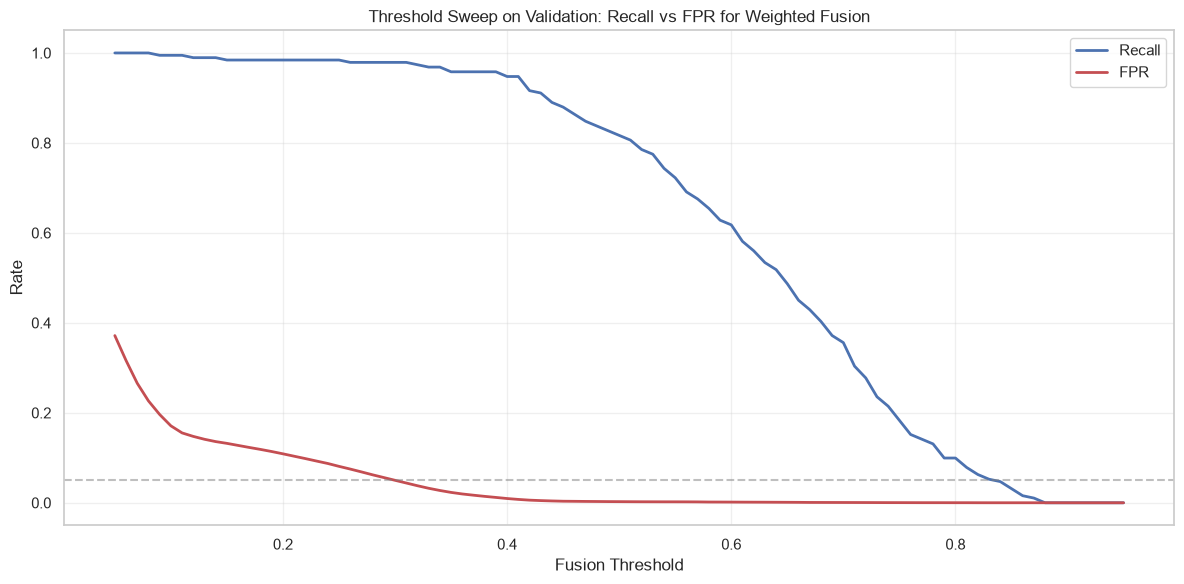


Optimal threshold on VALIDATION (FPR < 5%): 0.30
  Recall: 0.9791 | FPR: 0.0500

>>> FROZEN baseline threshold for held-out evaluation: 0.30


In [5]:
# Sweep thresholds from 0.05 to 0.95 — on the VALIDATION set only
thresholds = np.arange(0.05, 0.96, 0.01)
results = []

for t in thresholds:
    preds = (df_val['fused_score'] > t).astype(int)
    rec = recall_score(y_true_val, preds, zero_division=0)
    tn_i, fp_i, fn_i, tp_i = confusion_matrix(y_true_val, preds).ravel()
    fpr_i = fp_i / (fp_i + tn_i) if (fp_i + tn_i) > 0 else 0
    results.append({'threshold': t, 'recall': rec, 'fpr': fpr_i, 'tp': tp_i, 'fp': fp_i})

results_df = pd.DataFrame(results)

# Plot threshold sweep
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(results_df['threshold'], results_df['recall'], 'b-', label='Recall', linewidth=2)
ax1.plot(results_df['threshold'], results_df['fpr'], 'r-', label='FPR', linewidth=2)
ax1.set_xlabel('Fusion Threshold')
ax1.set_ylabel('Rate')
ax1.set_title('Threshold Sweep on Validation: Recall vs FPR for Weighted Fusion')
ax1.legend(loc='upper right')
ax1.axhline(y=0.05, color='gray', linestyle='--', alpha=0.5, label='5% FPR line')
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Find optimal: max recall where FPR < 5% (Validation)
acceptable = results_df[results_df['fpr'] < 0.05]
if len(acceptable) > 0:
    best = acceptable.loc[acceptable['recall'].idxmax()]
    print(f"\nOptimal threshold on VALIDATION (FPR < 5%): {best['threshold']:.2f}")
    print(f"  Recall: {best['recall']:.4f} | FPR: {best['fpr']:.4f}")
else:
    print("No threshold achieves FPR < 5%. Showing best trade-off...")
    # Youden's J statistic
    results_df['j_stat'] = results_df['recall'] - results_df['fpr']
    best = results_df.loc[results_df['j_stat'].idxmax()]
    print(f"  Best Youden's J threshold (Validation): {best['threshold']:.2f}")
    print(f"  Recall: {best['recall']:.4f} | FPR: {best['fpr']:.4f}")

# FREEZE the tuned parameter — the Test set has not been used anywhere above
FROZEN_THRESHOLD = float(best['threshold'])
print(f"\n>>> FROZEN baseline threshold for held-out evaluation: {FROZEN_THRESHOLD:.2f}")


## 5. Baseline Held-Out Test Evaluation (Frozen Threshold)
Apply the threshold tuned on Validation to the untouched Test set. These are the final, leakage-free numbers.

In [6]:
df_test['escalate'] = (df_test['fused_score'] > FROZEN_THRESHOLD).astype(int)

y_true_test = df_test['label']
y_pred_test = df_test['escalate']

test_recall = recall_score(y_true_test, y_pred_test, zero_division=0)
tn, fp, fn, tp = confusion_matrix(y_true_test, y_pred_test).ravel()
test_fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
test_auc = roc_auc_score(y_true_test, df_test['fused_score'])

print("=" * 55)
print("  BASELINE HELD-OUT TEST METRICS")
print("=" * 55)
print(f"  Frozen threshold:      {FROZEN_THRESHOLD:.2f}")
print(f"  Recall (TPR):          {test_recall:.4f} ({test_recall*100:.1f}%)")
print(f"  False Positive Rate:   {test_fpr:.4f} ({test_fpr*100:.1f}%)")
print(f"  ROC-AUC:               {test_auc:.4f}")
print(f"  Confusion Matrix:")
print(f"    TN={tn:,}  FP={fp:,}")
print(f"    FN={fn:,}  TP={tp:,}")
print("=" * 55)


  BASELINE HELD-OUT TEST METRICS
  Frozen threshold:      0.30
  Recall (TPR):          0.9154 (91.5%)
  False Positive Rate:   0.0542 (5.4%)
  ROC-AUC:               0.9842
  Confusion Matrix:
    TN=57,698  FP=3,304
    FN=17  TP=184


## 6. ROC Curve (Held-Out Test)

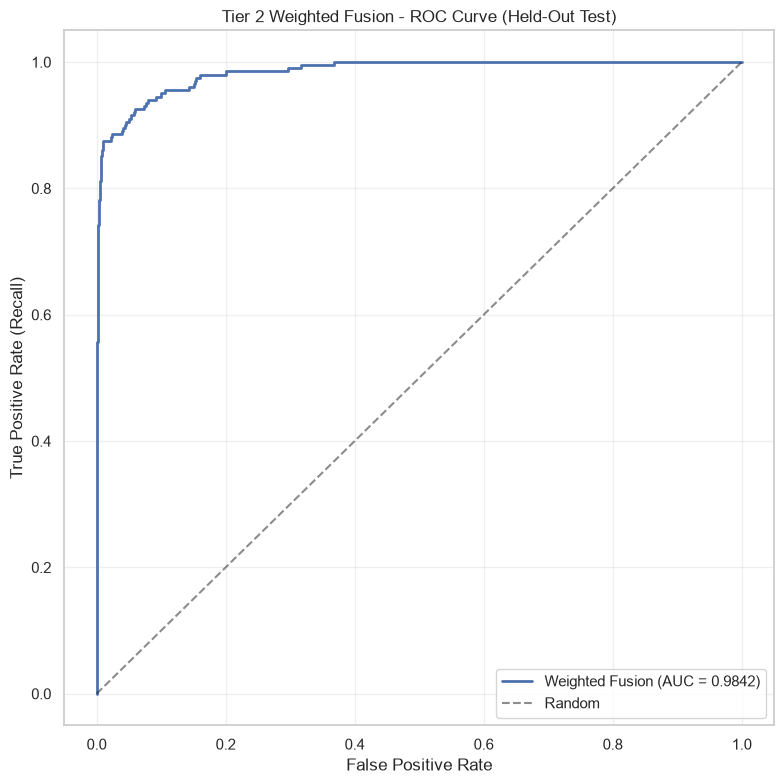

In [7]:
fpr_arr, tpr_arr, roc_thresholds = roc_curve(y_true_test, df_test['fused_score'])
roc_auc_val = roc_auc_score(y_true_test, df_test['fused_score'])

plt.figure(figsize=(8, 8))
plt.plot(fpr_arr, tpr_arr, 'b-', linewidth=2, label=f'Weighted Fusion (AUC = {roc_auc_val:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Tier 2 Weighted Fusion - ROC Curve (Held-Out Test)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Per-Scenario Breakdown (Held-Out Test)Analyze which insider threat scenarios the fusion system detects best.

In [8]:
# If the original data has scenario info, break down by scenario
# The 'label' column is binary (0/1), but we can check score distributions
# for true positives vs false negatives

tp_mask = (df_test['label'] == 1) & (df_test['escalate'] == 1)
fn_mask = (df_test['label'] == 1) & (df_test['escalate'] == 0)
fp_mask = (df_test['label'] == 0) & (df_test['escalate'] == 1)

print("Score distributions for detected vs missed threats:")
print(f"\n  True Positives (detected threats): {tp_mask.sum()}")
if tp_mask.sum() > 0:
    print(f"    HTTP score:       mean={df_test.loc[tp_mask, 'http_score'].mean():.4f}")
    print(f"    File/Device score: mean={df_test.loc[tp_mask, 'file_device_score'].mean():.4f}")
    print(f"    Logon score:      mean={df_test.loc[tp_mask, 'logon_score'].mean():.4f}")
    print(f"    Email score:      mean={df_test.loc[tp_mask, 'email_score'].mean():.4f}")

print(f"\n  False Negatives (missed threats): {fn_mask.sum()}")
if fn_mask.sum() > 0:
    print(f"    HTTP score:       mean={df_test.loc[fn_mask, 'http_score'].mean():.4f}")
    print(f"    File/Device score: mean={df_test.loc[fn_mask, 'file_device_score'].mean():.4f}")
    print(f"    Logon score:      mean={df_test.loc[fn_mask, 'logon_score'].mean():.4f}")
    print(f"    Email score:      mean={df_test.loc[fn_mask, 'email_score'].mean():.4f}")

print(f"\n  False Positives (false alarms): {fp_mask.sum()}")
if fp_mask.sum() > 0:
    print(f"    HTTP score:       mean={df_test.loc[fp_mask, 'http_score'].mean():.4f}")
    print(f"    File/Device score: mean={df_test.loc[fp_mask, 'file_device_score'].mean():.4f}")
    print(f"    Logon score:      mean={df_test.loc[fp_mask, 'logon_score'].mean():.4f}")
    print(f"    Email score:      mean={df_test.loc[fp_mask, 'email_score'].mean():.4f}")

Score distributions for detected vs missed threats:

  True Positives (detected threats): 184
    HTTP score:       mean=0.9197
    File/Device score: mean=0.5414
    Logon score:      mean=0.2275
    Email score:      mean=0.3730

  False Negatives (missed threats): 17
    HTTP score:       mean=0.0409
    File/Device score: mean=0.2851
    Logon score:      mean=0.1667
    Email score:      mean=0.2091

  False Positives (false alarms): 3304
    HTTP score:       mean=0.0999
    File/Device score: mean=0.7314
    Logon score:      mean=0.2196
    Email score:      mean=0.1852


## 8. Comparison vs Week-1 Binary RF Baseline

The core argument for the hierarchical design: does fusion improve over the **Week-1 binary Random Forest** (`week1_random_forest_binary.ipynb`)?

The comparison uses the **existing Week-1 baseline protocol unchanged**: same processed features (`data/processed/features_clean.parquet`), same canonical 60/20/20 user split (`data/user_splits/`), same RF hyperparameters (`n_estimators=200`, `class_weight='balanced'`, `random_state=42`), same threshold calibration on validation users only (Youden's J), evaluated once on the held-out test users.

Replicating the existing Week-1 Binary RF baseline (week1_random_forest_binary.ipynb)...
[OK] Week-1 Binary RF trained on TRAIN users only.
[Week-1 RF] Youden's-J threshold on validation: 0.05 (J=0.8307) — frozen.
Week-1 RF: Acc=0.9900 | Precision=0.1812 | Recall=0.6418 | F1=0.2826 | FPR=0.0089 | AUC=0.9410
Confusion: TN=64896 FP=583 FN=72 TP=129


### Final Comparison Table


| Metric | Week-1 Random Forest Binary | Fusion Agent (Held-Out Test) |
| :--- | :--- | :--- |
| **Recall (TPR)** | 0.6418 | 0.9154 |
| **FPR** | 0.0089 | 0.0542 |
| **Precision** | 0.1812 | 0.0528 |
| **F1** | 0.2826 | 0.0998 |
| **Accuracy** | 0.9900 | 0.9457 |
| **ROC-AUC** | 0.9410 | 0.9842 |


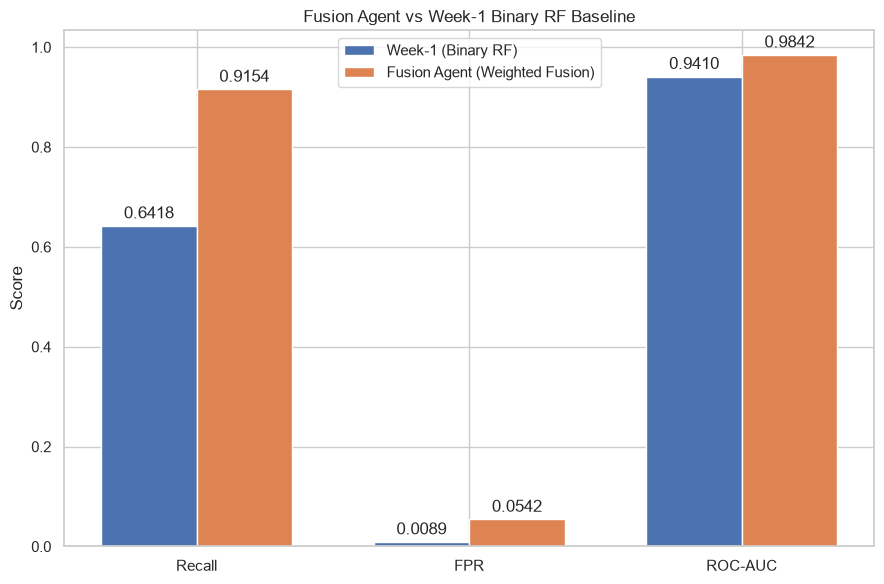


Saved: baseline_comparison.png


In [9]:
# --- Week-1 Random Forest Binary baseline (exact protocol from week1_random_forest_binary.ipynb) ---
# Loads the SAME processed features + canonical 60/20/20 user split, trains RF
# (n_estimators=200, class_weight='balanced', random_state=42) on TRAIN users,
# calibrates the decision threshold on VALIDATION users only via Youden's J,
# then evaluates ONCE on the held-out test users. This is the existing Week-1
# baseline — not a new model, not tuned or optimized here.
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
import warnings
warnings.filterwarnings('ignore')

print("Replicating the existing Week-1 Binary RF baseline "
      "(week1_random_forest_binary.ipynb)...")
X_w1 = pd.read_parquet(PROJECT_ROOT / 'data' / 'processed' / 'features_clean.parquet')

tr_u = np.load(PROJECT_ROOT / 'data' / 'user_splits' / 'train_users.npy')
va_u = np.load(PROJECT_ROOT / 'data' / 'user_splits' / 'val_users.npy')
te_u = np.load(PROJECT_ROOT / 'data' / 'user_splits' / 'test_users.npy')

tr_df = X_w1[X_w1['user'].isin(tr_u)]
va_df = X_w1[X_w1['user'].isin(va_u)]
te_df = X_w1[X_w1['user'].isin(te_u)]
feature_cols_w1 = [c for c in X_w1.columns if c not in ('user', 'insider')]

Xtr = tr_df[feature_cols_w1]; ytr = tr_df['insider'].astype(int).values
Xva = va_df[feature_cols_w1]; yva = va_df['insider'].astype(int).values
Xte = te_df[feature_cols_w1]; yte = te_df['insider'].astype(int).values

model_w1 = RandomForestClassifier(
    n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1,
)
model_w1.fit(Xtr, ytr)
print("[OK] Week-1 Binary RF trained on TRAIN users only.")

# --- Threshold calibration on VALIDATION only (Youden's J), frozen before test ---
p_va = model_w1.predict_proba(Xva)[:, 1]
best_j, best_t = -1.0, 0.5
for t in np.arange(0.05, 0.96, 0.05):
    preds = (p_va > t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yva, preds).ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    rec = recall_score(yva, preds, zero_division=0)
    j = rec - fpr
    if j > best_j:
        best_j, best_t = j, t
W1_THRESHOLD = float(best_t)
print(f"[Week-1 RF] Youden's-J threshold on validation: {W1_THRESHOLD:.2f} "
      f"(J={best_j:.4f}) — frozen.")

# --- Evaluate ONCE on the held-out test users ---
p_te = model_w1.predict_proba(Xte)[:, 1]
y_pred_w1 = (p_te > W1_THRESHOLD).astype(int)
w1_acc  = accuracy_score(yte, y_pred_w1)
w1_prec = precision_score(yte, y_pred_w1, zero_division=0)
w1_rec  = recall_score(yte, y_pred_w1, zero_division=0)
w1_f1   = f1_score(yte, y_pred_w1, zero_division=0)
w1_auc  = roc_auc_score(yte, p_te)
tn_w1, fp_w1, fn_w1, tp_w1 = confusion_matrix(yte, y_pred_w1).ravel()
w1_fpr  = fp_w1 / (fp_w1 + tn_w1) if (fp_w1 + tn_w1) > 0 else 0
print(f"Week-1 RF: Acc={w1_acc:.4f} | Precision={w1_prec:.4f} | Recall={w1_rec:.4f} "
      f"| F1={w1_f1:.4f} | FPR={w1_fpr:.4f} | AUC={w1_auc:.4f}")
print(f"Confusion: TN={tn_w1} FP={fp_w1} FN={fn_w1} TP={tp_w1}")

# --- Fusion Agent metrics (held-out test at the frozen threshold, same metric family) ---
f_acc  = accuracy_score(y_true_test, y_pred_test)
f_prec = precision_score(y_true_test, y_pred_test, zero_division=0)
f_f1   = f1_score(y_true_test, y_pred_test, zero_division=0)

comparison_table = f"""
| Metric | Week-1 Random Forest Binary | Fusion Agent (Held-Out Test) |
| :--- | :--- | :--- |
| **Recall (TPR)** | {w1_rec:.4f} | {test_recall:.4f} |
| **FPR** | {w1_fpr:.4f} | {test_fpr:.4f} |
| **Precision** | {w1_prec:.4f} | {f_prec:.4f} |
| **F1** | {w1_f1:.4f} | {f_f1:.4f} |
| **Accuracy** | {w1_acc:.4f} | {f_acc:.4f} |
| **ROC-AUC** | {w1_auc:.4f} | {test_auc:.4f} |
"""
display(Markdown("### Final Comparison Table"))
display(Markdown(comparison_table))

# Bar chart comparison (Recall, FPR, ROC-AUC — same chart as before)
labels = ['Recall', 'FPR', 'ROC-AUC']
w1_vals = [w1_rec, w1_fpr, w1_auc]
w3_vals = [test_recall, test_fpr, test_auc]

x = np.arange(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 6))
bars1 = ax.bar(x - width/2, w1_vals, width, label='Week-1 (Binary RF)', color='#4C72B0')
bars2 = ax.bar(x + width/2, w3_vals, width, label='Fusion Agent (Weighted Fusion)', color='#DD8452')

ax.set_ylabel('Score')
ax.set_title('Fusion Agent vs Week-1 Binary RF Baseline')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.4f}', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

plt.tight_layout()
plt.savefig(WEEK3_DIR / "baseline_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved: baseline_comparison.png")


## 9. Weight Sensitivity Analysis (on Validation)Explore how different weight configurations affect performance.

In [10]:
# Try alternative weight schemes
weight_configs = {
    'Domain (40/40/10/10)': (0.40, 0.40, 0.10, 0.10),
    'Equal (25/25/25/25)': (0.25, 0.25, 0.25, 0.25),
    'HTTP-dominant (60/20/10/10)': (0.60, 0.20, 0.10, 0.10),
    'File-dominant (20/60/10/10)': (0.20, 0.60, 0.10, 0.10),
    'Recall-proportional': None,  # computed below from NEW validation scores
}

# Recall-proportional weights (normalized by each agent's recall on VALIDATION)
# Computed from the current validation scores — no stale hardcoded recalls.
recalls = {
    'http': recall_score(y_true_val, (df_val['http_score'] > 0.5).astype(int), zero_division=0),
    'file': recall_score(y_true_val, (df_val['file_device_score'] > 0.5).astype(int), zero_division=0),
    'logon': recall_score(y_true_val, (df_val['logon_score'] > 0.5).astype(int), zero_division=0),
    'email': recall_score(y_true_val, (df_val['email_score'] > 0.5).astype(int), zero_division=0),
}
total_rec = sum(recalls.values())
weight_configs['Recall-proportional'] = (
    recalls['http']/total_rec, recalls['file']/total_rec,
    recalls['logon']/total_rec, recalls['email']/total_rec
)

print(f"{'Config':<30} {'Recall':>8} {'FPR':>8} {'AUC':>8}")
print("-" * 60)
for name, (wh, wf, wl, we) in weight_configs.items():
    scores = df_val['http_score']*wh + df_val['file_device_score']*wf + df_val['logon_score']*wl + df_val['email_score']*we
    preds = (scores > 0.5).astype(int)
    rec = recall_score(y_true_val, preds, zero_division=0)
    tn_i, fp_i, fn_i, tp_i = confusion_matrix(y_true_val, preds).ravel()
    fpr_i = fp_i / (fp_i + tn_i) if (fp_i + tn_i) > 0 else 0
    auc_i = roc_auc_score(y_true_val, scores)
    print(f"{name:<30} {rec:>8.4f} {fpr_i:>8.4f} {auc_i:>8.4f}")


Config                           Recall      FPR      AUC
------------------------------------------------------------
Domain (40/40/10/10)             0.8168   0.0025   0.9948
Equal (25/25/25/25)              0.4764   0.0009   0.9932
HTTP-dominant (60/20/10/10)      0.9319   0.0051   0.9960
File-dominant (20/60/10/10)      0.6021   0.0228   0.9670
Recall-proportional              0.9319   0.0046   0.9961
